# 07MIAR · Clasificación de residuos con RealWaste

**Asignatura:** Redes Neuronales y Deep Learning  
**Integrantes:**  
Nathalie Alejandra Véliz Godoy

Constanza de los Angeles Solá

Angel Eduardo Calizaya Morales



RealWaste contiene fotografías tomadas en un vertedero, con cambios de iluminación, objetos deformados o sucios de distintos materiales y fondos similares entre sí. La tarea consiste en asignar a cada foto la categoría indicada en su etiqueta. Se comparan una CNN propia, MobileNetV2 y EfficientNetB0 para investigar cuánto aporta el preentrenamiento en ImageNet y si el ajuste fino mejora el reconocimiento de clases con menos ejemplos.

El notebook se ejecutó completo en Google Colab con GPU. La descarga y la preparación de los datos se realizan dentro del propio notebook.

> **Resumen.** Comparamos una CNN diseñada desde cero con dos redes preentrenadas en ImageNet (MobileNetV2 y EfficientNetB0) para clasificar 9 tipos de residuos. La mejor fue **EfficientNetB0 con fine-tuning (F1 macro 0,79 en test)**. El hallazgo principal fue que la CNN propia estaba subentrenada: al entrenarla más tiempo pasó de 0,69 a 0,77 en validación y quedó prácticamente igual que MobileNetV2 en test (0,75 frente a 0,76), con casi 30 veces menos parámetros que MobileNetV2 y unas 50 veces menos que EfficientNetB0.

### Justificación del conjunto de datos

Elegimos **RealWaste** por tres motivos:

1. **Es un problema real con aplicación directa.** Clasificar residuos por material es un paso clave para automatizar el reciclaje. El conjunto está documentado en un artículo científico (Single, Iranmanesh y Raad, 2023) y publicado en el repositorio UCI.
2. **Cumple los requisitos de la actividad.** Es un problema de clasificación de imágenes con **9 categorías bien definidas** (cartón, orgánicos, vidrio, metal, residuos varios, papel, plástico, textil y vegetación) y **4.752 imágenes** etiquetadas por carpeta.
3. **Es exigente de forma interesante.** Las fotos se tomaron en un vertedero, con objetos deformados, sucios o mezclados, y cambios de iluminación. Además, el conjunto es **pequeño y desbalanceado**. Ese es el escenario en el que la comparación entre entrenar desde cero y reutilizar una red preentrenada resulta más informativa.

| Característica | Valor |
|---|---|
| N.º de imágenes | 4.752 (todas utilizables, del repositorio UCI) |
| N.º de clases | 9: Cardboard, Food Organics, Glass, Metal, Miscellaneous Trash, Paper, Plastic, Textile Trash y Vegetation |
| Dimensiones | 524 × 524 px, RGB (todas iguales); redimensionadas a 128 × 128 para el entrenamiento |
| Distribución | Desbalanceada, casi 3 a 1: de 921 (Plastic, 19,4 %) a 318 (Textile Trash, 6,7 %) |

## 1. Configuración reproducible

Usamos entradas RGB de 128 × 128 para limitar el coste de repetir los experimentos con las tres arquitecturas, aunque esta reducción puede perder detalles finos de algunos residuos. Mantenemos la misma semilla, resolución, partición y métrica de selección durante toda la comparación. Además, registramos el entorno de ejecución, porque la reproducibilidad numérica puede variar entre dispositivos y versiones.

In [ ]:
import hashlib
import os
import shutil
import tempfile
from datetime import datetime
from pathlib import Path, PurePosixPath
from time import perf_counter
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
PROFILE = os.environ.get("REALWASTE_PROFILE", "completo")
if PROFILE not in {"completo", "verificacion"}:
    raise ValueError("Usar el perfil completo o verificacion.")

QUICK = PROFILE == "verificacion"
EPOCHS = {"cnn": 1, "cnn_largo": 1, "transfer": 1, "fine_tuning": 1} if QUICK else {
    "cnn": 15, "cnn_largo": 40, "transfer": 12, "fine_tuning": 10,
}
keras.utils.set_random_seed(SEED)

WORK_DIR = Path(os.environ.get("REALWASTE_WORK_DIR", "realwaste_trabajo")).expanduser().resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR = WORK_DIR / "ejecuciones" / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
RUN_DIR.mkdir(parents=True)

gpu_names = [device.name for device in tf.config.list_physical_devices("GPU")]
print(f"TensorFlow {tf.__version__} / Keras {keras.__version__}")
print(f"Perfil: {PROFILE} | GPU: {gpu_names or 'CPU'} | Semilla: {SEED}")
print(f"Imagen: {IMAGE_SIZE} | Batch: {BATCH_SIZE} | Épocas máximas: {EPOCHS}")

TensorFlow 2.21.0 / Keras 3.13.2
Perfil: completo | GPU: ['/physical_device:GPU:0'] | Semilla: 42
Imagen: (128, 128) | Batch: 32 | Épocas máximas: {'cnn': 15, 'cnn_largo': 40, 'transfer': 12, 'fine_tuning': 10}


## 2. Carga, inspección y control de calidad

Usamos la distribución pública de UCI, que documenta 4.752 imágenes de 524 × 524 y nueve clases. Las etiquetas se obtienen del nombre de cada carpeta. La inspección comprueba que las cantidades coinciden con las publicadas, lee las dimensiones reales y verifica que todas las imágenes se puedan decodificar.

También buscamos duplicados exactos mediante un *hash* de los píxeles RGB originales, ya que un mismo contenido puede guardarse en dos archivos distintos. Si varias copias tienen la misma etiqueta, conservamos una; si comparten píxeles pero tienen etiquetas distintas, excluimos el grupo por ambiguo. Este control solo detecta copias idénticas: tomas muy parecidas de un mismo objeto requerirían un control adicional.

Fuentes: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/908/realwaste) · [Artículo de Single, Iranmanesh y Raad (2023)](https://doi.org/10.3390/info14120633).

In [ ]:
DATA_URL = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"
PUBLISHED_COUNTS = {
    "Cardboard": 461,
    "Food Organics": 411,
    "Glass": 420,
    "Metal": 790,
    "Miscellaneous Trash": 495,
    "Paper": 500,
    "Plastic": 921,
    "Textile Trash": 318,
    "Vegetation": 436,
}
CLASS_NAMES = list(PUBLISHED_COUNTS)
NUM_CLASSES = len(CLASS_NAMES)


def prepare_realwaste(work_dir):
    image_dir = work_dir / "imagenes_uci_908"
    if image_dir.is_dir():
        return image_dir

    local_zip = os.environ.get("REALWASTE_ARCHIVE")
    archive = Path(local_zip).expanduser() if local_zip else Path(keras.utils.get_file(
        fname="realwaste-uci-908.zip",
        origin=DATA_URL,
        cache_dir=str(work_dir),
        cache_subdir="descargas",
    ))

    # Solo se extraen JPEG de las carpetas de clase conocidas.
    with ZipFile(archive) as zip_file, tempfile.TemporaryDirectory(dir=work_dir) as temp_dir:
        staged = Path(temp_dir) / image_dir.name
        for class_name in CLASS_NAMES:
            (staged / class_name).mkdir(parents=True)

        for member in zip_file.infolist():
            parts = PurePosixPath(member.filename).parts
            if (
                member.is_dir() or len(parts) < 3 or parts[-3] != "RealWaste"
                or parts[-2] not in PUBLISHED_COUNTS
                or PurePosixPath(parts[-1]).suffix.lower() not in {".jpg", ".jpeg"}
            ):
                continue
            target = staged / parts[-2] / parts[-1]
            with zip_file.open(member) as source, target.open("xb") as output:
                shutil.copyfileobj(source, output)

        counts = {name: len(list((staged / name).iterdir())) for name in CLASS_NAMES}
        if counts != PUBLISHED_COUNTS:
            raise ValueError(f"El ZIP no coincide con la distribución de UCI: {counts}")
        staged.rename(image_dir)
    return image_dir


DATA_DIR = prepare_realwaste(WORK_DIR)
print(DATA_DIR)

687603712/Unknown 45s 0us/step/content/realwaste_trabajo/imagenes_uci_908


Leídas: 4,752 | No legibles: 0
Copias retiradas con igual etiqueta: 0
Imágenes retiradas por etiquetas contradictorias: 0
Imágenes utilizables: 4,752


,ancho,alto,imágenes
0,524,524,4752


,UCI,Leídas,Utilizables,Proporción (%)
Cardboard,461,461,461,9.70
Food Organics,411,411,411,8.65
Glass,420,420,420,8.84
Metal,790,790,790,16.62
Miscellaneous Trash,495,495,495,10.42
Paper,500,500,500,10.52
Plastic,921,921,921,19.38
Textile Trash,318,318,318,6.69
Vegetation,436,436,436,9.18


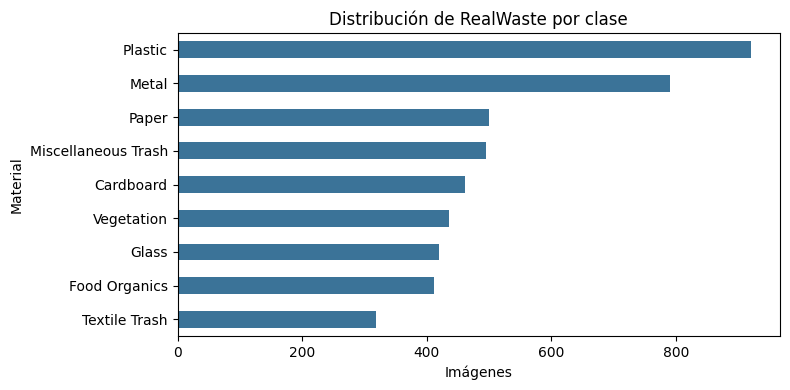

In [ ]:
records = []
unreadable = []
for label, material in enumerate(CLASS_NAMES):
    for path in sorted((DATA_DIR / material).iterdir()):
        try:
            with Image.open(path) as source:
                rgb = source.convert("RGB")
                pixel_hash = hashlib.sha256(rgb.tobytes()).hexdigest()
                width, height = rgb.size
        except (OSError, ValueError) as error:
            unreadable.append({"archivo": path.name, "error": str(error)})
            continue
        records.append({
            "ruta": str(path), "material": material, "etiqueta": label,
            "ancho": width, "alto": height, "huella": f"{width}x{height}:{pixel_hash}",
        })

raw = pd.DataFrame(records)
label_counts = raw.groupby("huella")["etiqueta"].transform("nunique")
conflicting = label_counts > 1
consistent = raw.loc[~conflicting]
images = consistent.drop_duplicates(subset="huella").reset_index(drop=True)

distribution = pd.DataFrame({
    "UCI": pd.Series(PUBLISHED_COUNTS),
    "Leídas": raw["material"].value_counts(),
    "Utilizables": images["material"].value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
distribution["Proporción (%)"] = (100 * distribution["Utilizables"] / len(images)).round(2)

print(f"Leídas: {len(raw):,} | No legibles: {len(unreadable):,}")
print(f"Copias retiradas con igual etiqueta: {len(consistent) - len(images):,}")
print(f"Imágenes retiradas por etiquetas contradictorias: {int(conflicting.sum()):,}")
print(f"Imágenes utilizables: {len(images):,}")
if unreadable:
    display(pd.DataFrame(unreadable).head())
display(raw.groupby(["ancho", "alto"]).size().rename("imágenes").reset_index())
display(distribution)

ax = distribution["Utilizables"].sort_values().plot.barh(figsize=(8, 4), color="#3b7398")
ax.set(xlabel="Imágenes", ylabel="Material", title="Distribución de RealWaste por clase")
plt.tight_layout()
plt.show()

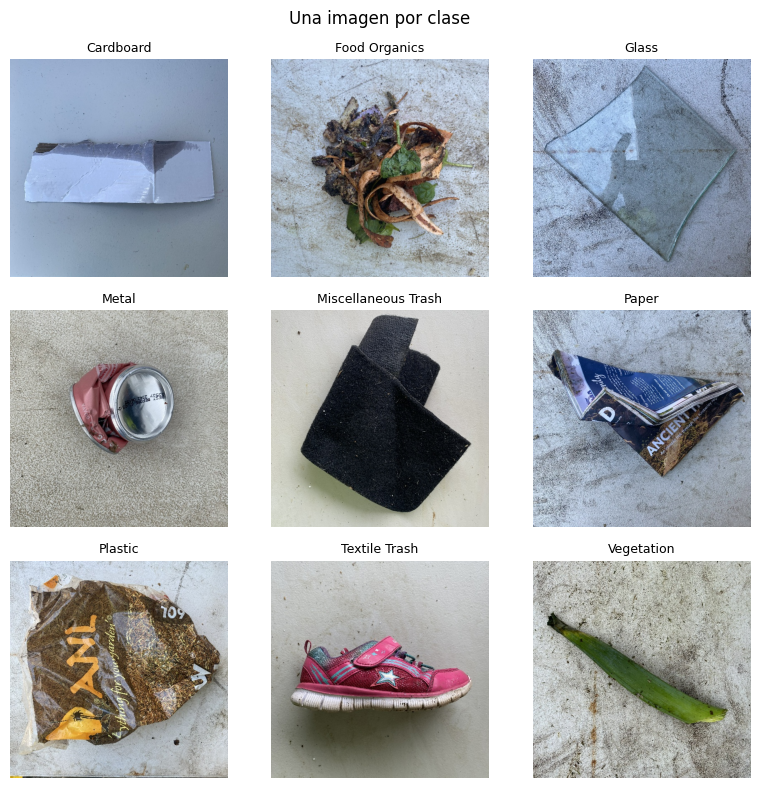

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for material, ax in zip(CLASS_NAMES, axes.flat):
    path = images.loc[images["material"] == material, "ruta"].sample(
        n=1, random_state=SEED,
    ).iloc[0]
    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(material, fontsize=9)
    ax.axis("off")
fig.suptitle("Una imagen por clase")
fig.tight_layout()
plt.show()

### Conclusiones de la inspección

- **Calidad de los datos.** Las 4.752 imágenes se pueden decodificar y coinciden con los conteos publicados por UCI. No hay duplicados exactos ni etiquetas contradictorias, así que no fue necesario descartar ninguna.
- **Tamaño homogéneo.** Todas las imágenes miden 524 × 524 px. El redimensionado a 128 × 128 es uniforme y no deforma los objetos. A cambio, puede perder detalles finos de textura que ayudan a distinguir materiales; lo tenemos en cuenta como limitación.
- **Desbalance de casi 3 a 1.** Plastic (921) y Metal (790) dominan, mientras que Textile Trash (318) es la clase más pequeña. Por eso usamos **F1 macro** como métrica principal, que da el mismo peso a todas las clases, y comparamos siempre contra un clasificador trivial que predice la clase mayoritaria.
- **Fondo poco informativo.** La mayoría de las fotos tienen un fondo gris o de concreto parecido. Esto obliga al modelo a fijarse en el objeto y no en el entorno.
- **Posibles confusiones.** A partir de los ejemplos anticipamos tres pares difíciles: *Miscellaneous Trash* con *Textile Trash* (telas oscuras), *Cardboard* con *Paper* (cartón delgado y claro) y *Plastic* con *Paper* (envases impresos). Además, *Textile Trash* es muy heterogénea (incluye desde calzado hasta telas). Contrastaremos estas hipótesis con las matrices de confusión de la sección 7.

## 3. Partición y preprocesamiento

Construimos una partición estratificada por clase de aproximadamente 70 % para entrenamiento, 15 % para validación y 15 % para test (el redondeo se aplica por clase). La estratificación garantiza que cada clase conserve la misma proporción en los tres subconjuntos; con clases pequeñas como Textile Trash, una partición al azar podría dejar el test con muy pocos ejemplos de esa clase. La validación decide las épocas y las variantes, y el test queda reservado para evaluar, al final de todos los ajustes, la CNN propia elegida y la mejor fase de cada red preentrenada.

Cada imagen se convierte a RGB y se redimensiona con interpolación bilineal y *antialiasing*. Guardamos en memoria los píxeles redimensionados (8 bits) para no volver a decodificar los JPEG en cada época. La entrada conserva la escala [0, 255] para que cada modelo aplique su propio preprocesamiento. Durante el entrenamiento barajamos los ejemplos, mientras que en la evaluación se conserva su orden. El aumento de datos se aplica dentro del modelo durante el entrenamiento y queda desactivado en validación y test.

In [ ]:
def stratified_partitions(frame, seed):
    rng = np.random.default_rng(seed)
    indices = {"train": [], "val": [], "test": []}

    for _, group in frame.groupby("etiqueta", sort=True):
        if len(group) < 7:
            raise ValueError("Se necesitan al menos siete imágenes por clase para la partición.")
        permuted = rng.permutation(group.index.to_numpy())
        holdout_size = round(0.15 * len(permuted))
        train_end = len(permuted) - 2 * holdout_size
        indices["train"].extend(permuted[:train_end])
        indices["val"].extend(permuted[train_end:-holdout_size])
        indices["test"].extend(permuted[-holdout_size:])

    return {
        name: frame.loc[sorted(rows)].reset_index(drop=True)
        for name, rows in indices.items()
    }


splits = stratified_partitions(images, SEED)
split_counts = pd.DataFrame({
    name: frame["material"].value_counts()
    for name, frame in splits.items()
}).reindex(CLASS_NAMES)
used_hashes = pd.concat(splits.values())["huella"]
assert len(used_hashes) == len(images) and used_hashes.is_unique
assert split_counts.notna().all().all()
display(split_counts.assign(Total=split_counts.sum(axis=1)))
print("Totales:", split_counts.sum().to_dict())

if QUICK:
    limits = {"train": 10, "val": 4, "test": 4}
    splits = {
        name: pd.concat([
            group.sample(n=min(limits[name], len(group)), random_state=SEED)
            for _, group in frame.groupby("etiqueta", sort=True)
        ]).sort_index().reset_index(drop=True)
        for name, frame in splits.items()
    }
    print("Imágenes usadas en la verificación:", {name: len(df) for name, df in splits.items()})

for name, frame in splits.items():
    frame.to_csv(RUN_DIR / f"{name}.csv", index=False)

,train,val,test,Total
material,,,,
Cardboard,323,69,69,461
Food Organics,287,62,62,411
Glass,294,63,63,420
Metal,554,118,118,790
Miscellaneous Trash,347,74,74,495
Paper,350,75,75,500
Plastic,645,138,138,921
Textile Trash,222,48,48,318
Vegetation,306,65,65,436


Totales: {'train': 3328, 'val': 712, 'test': 712}


In [ ]:
def decode_image(path, label):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, IMAGE_SIZE, antialias=True)
    image = tf.saturate_cast(tf.round(image), tf.uint8)
    return image, tf.one_hot(label, NUM_CLASSES)


def decode_partition(frame):
    paths = frame["ruta"].to_numpy(dtype=str)
    labels = frame["etiqueta"].to_numpy(dtype=np.int32)
    return tf.data.Dataset.from_tensor_slices((paths, labels)).map(
        decode_image, num_parallel_calls=tf.data.AUTOTUNE,
    )


def batch_and_prefetch(dataset):
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


batch_images, batch_labels = next(iter(decode_partition(splits["train"].head(BATCH_SIZE)).batch(BATCH_SIZE)))
print("Forma del lote:", batch_images.shape, "| Etiquetas:", batch_labels.shape)
print("Rango de píxeles:", int(tf.reduce_min(batch_images)), int(tf.reduce_max(batch_images)))

train_images = decode_partition(splits["train"]).cache()
val_ds = batch_and_prefetch(decode_partition(splits["val"]).cache())
test_ds = batch_and_prefetch(decode_partition(splits["test"]).cache())


def training_dataset():
    shuffled = train_images.shuffle(
        len(splits["train"]), seed=SEED, reshuffle_each_iteration=True,
    )
    return batch_and_prefetch(shuffled)

Forma del lote: (32, 128, 128, 3) | Etiquetas: (32, 9)
Rango de píxeles: 0 253


## 4. Protocolo de entrenamiento y selección

La métrica principal es el **F1 macro**, que promedia el F1 de las nueve clases con el mismo peso; también registramos la exactitud (*accuracy*) y la pérdida. Como referencia mínima usamos un clasificador trivial que predice siempre la clase mayoritaria de entrenamiento.

Todos los modelos se entrenan con Adam y entropía cruzada categórica. En cada entrenamiento guardamos el punto con mejor F1 macro de validación, reducimos la tasa de aprendizaje a la mitad cuando la mejora se estanca (`ReduceLROnPlateau`) y aplicamos parada temprana (`EarlyStopping`, paciencia de 4 épocas). Al comparar dos variantes, solo cambiamos de modelo si la nueva mejora el F1 de validación; en caso de empate mantenemos la anterior. Los tiempos corresponden al entrenamiento en este entorno, y en las redes preentrenadas se informan por fase.

**Nota sobre la brecha.** Keras calcula las métricas de entrenamiento con el dropout y el aumento de datos activos, mientras que las de validación se calculan sin ellos. Por eso, en los modelos que usan esas técnicas, la brecha entre entrenamiento y validación es un **límite inferior** del sobreajuste real.

In [ ]:
MONITOR = "val_f1_macro"
histories = {}
runs = {}
weight_paths = {}


def augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.06, fill_mode="reflect", seed=SEED + 1),
        layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED + 2),
    ], name="aumento_datos")


def train_model(model, run, family, phase, learning_rate, max_epochs):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.CategoricalCrossentropy(),
        jit_compile=False,
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.F1Score(average="macro", name="f1_macro"),
        ],
    )

    checkpoint = RUN_DIR / f"{run}.weights.h5"
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            checkpoint, monitor=MONITOR, mode="max", save_best_only=True, save_weights_only=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor=MONITOR, mode="max", factor=0.5, patience=2, min_delta=0.001,
        ),
        keras.callbacks.EarlyStopping(
            monitor=MONITOR, mode="max", patience=4, min_delta=0.0,
        ),
    ]

    trainable = sum(int(np.prod(weight.shape)) for weight in model.trainable_weights)
    print(f"{run}: {trainable:,} parámetros entrenables | LR={learning_rate:g}")
    start = perf_counter()
    history = model.fit(
        training_dataset(),
        validation_data=val_ds, epochs=max_epochs, callbacks=callbacks, shuffle=False, verbose=2,
    )
    elapsed = perf_counter() - start
    model.load_weights(checkpoint)

    log = pd.DataFrame(history.history)
    log.index = pd.RangeIndex(1, len(log) + 1, name="epoca")
    log.to_csv(RUN_DIR / f"{run}_curvas.csv")
    epoch = int(log[MONITOR].idxmax())
    best = log.loc[epoch]

    histories[run] = log
    weight_paths[run] = checkpoint
    runs[run] = {
        "familia": family, "fase": phase, "lr_inicial": learning_rate,
        "parametros_totales": model.count_params(), "parametros_entrenables": trainable,
        "epocas": len(log), "mejor_epoca": epoch, "segundos": elapsed,
        "f1_train": float(best["f1_macro"]), "f1_val": float(best[MONITOR]),
        "acc_val": float(best["val_accuracy"]),
        "brecha_f1": float(best["f1_macro"] - best[MONITOR]),
    }
    return runs[run]


def compare_validation(candidate, reference, change):
    delta = runs[candidate]["f1_val"] - runs[reference]["f1_val"]
    chosen = candidate if delta > 0 else reference
    print(f"{change}: variación F1 macro = {delta:+.4f}. Se selecciona {chosen}.")
    return chosen


def show_curves(run_ids):
    fig, axes = plt.subplots(len(run_ids), 2, figsize=(10, 2.65 * len(run_ids)), squeeze=False)
    for run, (loss_ax, f1_ax) in zip(run_ids, axes):
        history = histories[run]
        loss_ax.plot(history.index, history["loss"], "o-", ms=3, label="Entrenamiento")
        loss_ax.plot(history.index, history["val_loss"], "o-", ms=3, label="Validación")
        f1_ax.plot(history.index, history["f1_macro"], "o-", ms=3, label="Entrenamiento")
        f1_ax.plot(history.index, history["val_f1_macro"], "o-", ms=3, label="Validación")
        f1_ax.axvline(runs[run]["mejor_epoca"], color="0.5", linestyle=":", label="Época elegida")
        loss_ax.set(title=f"{run} · pérdida", xlabel="Época")
        f1_ax.set(title=f"{run} · F1 macro", xlabel="Época", ylim=(0, 1))
    axes[0, 0].legend(loc="best", fontsize="small")
    axes[0, 1].legend(loc="best", fontsize="small")
    fig.tight_layout()
    plt.show()

## 5. CNN diseñada y entrenada desde cero

Partimos de un modelo base con tres bloques convolucionales (convoluciones de 3 × 3, ReLU y *max pooling*) y una cabeza con *global average pooling* y nueve salidas *softmax*; la última convolución tiene 64 filtros. Después probamos añadir un cuarto bloque de 96 filtros para ampliar la capacidad y el campo receptivo.

A partir de la mejor variante, evaluamos una decisión a la vez:

1. **Batch normalization** antes de ReLU, para estudiar si estabiliza el entrenamiento.
2. **Penalización L2 y dropout**, para intentar reducir el sobreajuste. En esta primera serie se prueban juntos, por lo que el resultado refleja su efecto combinado; en la sección 5.1 los separamos.
3. **Aumento geométrico**, para comprobar si las variaciones de orientación y encuadre mejoran la generalización. Evitamos cambios fuertes de color, que podrían alterar pistas del material.

Cada candidata se entrena desde cero y la modificación se conserva solo si mejora el F1 macro de validación. En la tabla de resultados, la columna *referencia* indica qué variante sirvió de base para cada decisión.

Model: "cnn_propia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,169 (94.41 KB)

 Trainable params: 24,169 (94.41 KB)

 Non-trainable params: 0 (0.00 B)

cnn_base: 24,169 parámetros entrenables | LR=0.001
Epoch 1/15
104/104 - 23s - 223ms/step - accuracy: 0.2082 - f1_macro: 0.0699 - loss: 2.1246 - val_accuracy: 0.2205 - val_f1_macro: 0.0831 - val_loss: 2.0237 - learning_rate: 0.0010
Epoch 2/15
104/104 - 1s - 11ms/step - accuracy: 0.2794 - f1_macro: 0.1602 - loss: 1.9434 - val_accuracy: 0.3104 - val_f1_macro: 0.2162 - val_loss: 1.8683 - learning_rate: 0.0010
Epoch 3/15
104/104 - 1s - 11ms/step - accuracy: 0.3459 - f1_macro: 0.2675 - loss: 1.8240 - val_accuracy: 0.3511 - val_f1_macro: 0.2855 - val_loss: 1.7888 - learning_rate: 0.0010
Epoch 4/15
104/104 - 2s - 16ms/step - accuracy: 0.3747 - f1_macro: 0.3163 - loss: 1.7474 - val_accuracy: 0.3469 - val_f1_macro: 0.2547 - val_loss: 1.8006 - learning_rate: 0.0010
Epoch 5/15
104/104 - 2s - 15ms/step - accuracy: 0.4014 - f1_macro: 0.3461 - loss: 1.7049 - val_accuracy: 0.4017 - val_f1_macro: 0.3170 - val_loss: 1.7010 - learning_rate: 0.0010
Epoch 6/15
104/104 - 2s - 20ms/step - accuracy: 0.4195 - 

,cambio,referencia,candidata,delta_f1_val,elegida
0,Cuarto bloque convolucional,cnn_base,cnn_profundidad,0.0939,cnn_profundidad
1,Batch normalization,cnn_profundidad,cnn_batchnorm,0.0744,cnn_batchnorm
2,L2 y dropout,cnn_batchnorm,cnn_l2_dropout,-0.0458,cnn_batchnorm
3,Aumento geométrico,cnn_batchnorm,cnn_aumento,-0.0544,cnn_batchnorm


,familia,fase,lr_inicial,parametros_totales,parametros_entrenables,epocas,mejor_epoca,segundos,f1_train,f1_val,acc_val,brecha_f1
cnn_base,CNN propia,desde cero,0.001,24169,24169,15,15,43.5383,0.5343,0.5172,0.5365,0.0171
cnn_profundidad,CNN propia,desde cero,0.001,79849,79849,15,15,24.7085,0.6194,0.6111,0.6208,0.0084
cnn_batchnorm,CNN propia,desde cero,0.001,80473,80057,15,13,43.6982,0.7298,0.6855,0.6840,0.0444
cnn_l2_dropout,CNN propia,desde cero,0.001,80473,80057,15,12,48.7109,0.6556,0.6397,0.6334,0.0159
cnn_aumento,CNN propia,desde cero,0.001,80473,80057,15,13,47.3723,0.6914,0.6311,0.6433,0.0603


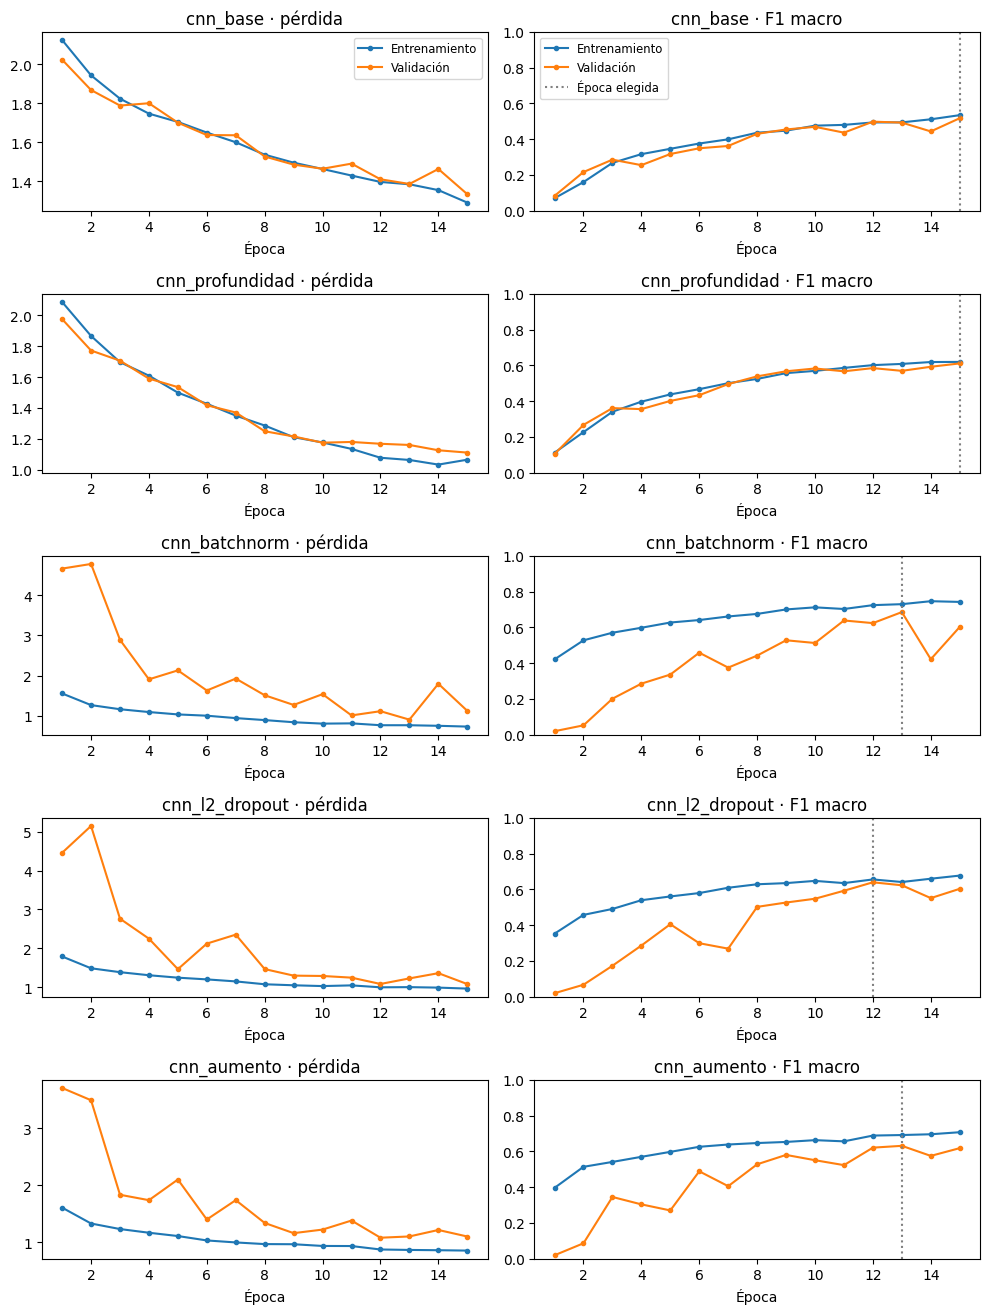

In [ ]:
def build_scratch(filters=(16, 32, 64), use_bn=False, regularized=False, augmented=False,
                  l2=None, dropout=None):
    # `regularized` reproduce el experimento original (L2 y dropout juntos).
    # `l2` y `dropout` permiten evaluar cada técnica por separado (sección 5.1).
    if regularized:
        l2 = 1e-4 if l2 is None else l2
        dropout = 0.30 if dropout is None else dropout
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="imagen")
    x = augmentation()(inputs) if augmented else inputs
    x = layers.Rescaling(1 / 255)(x)
    penalty = keras.regularizers.L2(l2) if l2 else None

    for width in filters:
        x = layers.Conv2D(
            width, kernel_size=3, padding="same", use_bias=not use_bn,
            kernel_initializer="he_normal", kernel_regularizer=penalty,
        )(x)
        if use_bn:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    if dropout:
        x = layers.Dropout(dropout, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", kernel_regularizer=penalty)(x)
    return keras.Model(inputs, outputs, name="cnn_propia")


scratch_specs = {}
scratch_comparisons = []


def run_scratch(run, spec, print_summary=False):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_scratch(**spec)
    if print_summary:
        model.summary()
    train_model(model, run, "CNN propia", "desde cero", 1e-3, EPOCHS["cnn"])
    scratch_specs[run] = spec


scratch_winner = "cnn_base"
run_scratch(scratch_winner, {"filters": (16, 32, 64)}, print_summary=True)

for name, change, update in [
    ("cnn_profundidad", "Cuarto bloque convolucional", {"filters": (16, 32, 64, 96)}),
    ("cnn_batchnorm", "Batch normalization", {"use_bn": True}),
    ("cnn_l2_dropout", "L2 y dropout", {"regularized": True}),
    ("cnn_aumento", "Aumento geométrico", {"augmented": True}),
]:
    reference = scratch_winner
    run_scratch(name, {**scratch_specs[reference], **update})
    scratch_winner = compare_validation(name, reference, change)
    scratch_comparisons.append({
        "cambio": change, "referencia": reference, "candidata": name,
        "delta_f1_val": runs[name]["f1_val"] - runs[reference]["f1_val"],
        "elegida": scratch_winner,
    })

print(f"CNN propia elegida: {scratch_winner}")
display(pd.DataFrame(scratch_comparisons).round(4))
display(pd.DataFrame.from_dict({run: runs[run] for run in scratch_specs}, orient="index").round(4))
show_curves(list(scratch_specs))

### Análisis de los experimentos de la CNN propia

| Experimento | Parámetros | F1 train | F1 val | Brecha | Mejor época |
|---|---|---|---|---|---|
| `cnn_base` | 24.169 | 0,53 | 0,52 | +0,02 | 15 de 15 |
| `cnn_profundidad` | 79.849 | 0,62 | 0,61 | +0,01 | 15 de 15 |
| `cnn_batchnorm` | 80.473 | 0,73 | **0,69** | +0,04 | 13 de 15 |
| `cnn_l2_dropout` | 80.473 | 0,66 | 0,64 | +0,02 | 12 de 15 |
| `cnn_aumento` | 80.473 | 0,69 | 0,63 | +0,06 | 13 de 15 |

**1. Modelo base → subajuste.** Con tres bloques y 24 mil parámetros, el F1 queda en torno a 0,52–0,53 tanto en entrenamiento como en validación, y la brecha es mínima. El modelo no memoriza: le falta capacidad para representar el problema. Además, su mejor época es la última, señal de que todavía no había terminado de aprender. **Decisión:** aumentar la capacidad.

**2. Más capacidad con un cuarto bloque convolucional (+0,09).** Más filtros y un campo receptivo mayor permiten capturar patrones de más alto nivel. La brecha sigue siendo mínima (+0,01) y la mejor época vuelve a ser la última: el modelo sigue en subajuste. **Decisión:** conservarlo.

**3. Batch normalization → mejora (+0,07) y es la mejor variante de esta serie.** Normalizar las activaciones acelera el aprendizaje: el F1 de entrenamiento sube a 0,73 y el de validación a 0,69, con una brecha de +0,04. Sin embargo, la curva de validación es **inestable**: en la época 14 el F1 cae de 0,69 a 0,42 y en la 15 se recupera solo parcialmente (0,60). Una posible causa, que no comprobamos directamente, es la diferencia entre las estadísticas del lote que la red usa al entrenar y las estadísticas acumuladas que usa al evaluar, combinada con una tasa de aprendizaje de 1e-3 que todavía mueve mucho los pesos. Que la caída desaparezca con una tasa de 3e-4 (sección 5.1) apoya la influencia de la tasa de aprendizaje.

**4. ¿Ayudan L2 y dropout? En esta serie, no (−0,05).** Estas técnicas atacan el **sobreajuste**, y efectivamente reducen la brecha de +0,04 a +0,02. Pero el modelo de partida apenas sobreajustaba, de modo que el beneficio es pequeño, mientras que el costo, un aprendizaje más lento, es evidente: en las primeras épocas el F1 de validación apenas llega a 0,02–0,07. Además, al probar las dos técnicas juntas no podemos saber cuál de ellas es responsable del resultado.

**5. Aumento de datos → empeora en validación (−0,05).** Al presentar variaciones de las imágenes, la tarea de entrenamiento se vuelve más difícil y la red necesita más épocas para converger. La validación oscila mucho y el mejor resultado aparece cerca del final.

**Diagnóstico.** El factor que más limita a la CNN propia es el **subajuste por entrenamiento corto**, no el sobreajuste: los modelos alcanzan su mejor época al final del límite de 15 y el *early stopping* nunca llega a activarse. Por eso, la conclusión de que la regularización y el aumento de datos "empeoran" es **prematura**: esas técnicas ralentizan el aprendizaje y con 15 épocas no tienen margen para mostrar su efecto. La sección 5.1 comprueba esta hipótesis.

**Decisiones fijadas sin experimentar.** Por el coste de cómputo, algunas decisiones se mantuvieron constantes en toda la serie: *kernels* de 3 × 3 (el tamaño estándar, que permite ampliar el campo receptivo apilando capas con menos parámetros que un *kernel* grande), activación ReLU, optimizador Adam y lotes de 32 imágenes. La tasa de aprendizaje sí se evalúa en la sección 5.1. Explorar el tamaño del *kernel* o del lote queda como línea de mejora.

### 5.1 Experimentos complementarios: entrenamiento más largo y técnicas por separado

El análisis anterior plantea dos problemas en el diseño experimental:

1. **Entrenamiento corto.** Con un máximo de 15 épocas los modelos todavía estaban mejorando, lo que penaliza a las técnicas que ralentizan el aprendizaje.
2. **Técnicas combinadas.** L2 y dropout se probaron juntos, así que no se puede atribuir el efecto a ninguna de las dos.

Para resolverlo, repetimos la secuencia con un máximo de **40 épocas** (el *early stopping* detiene el entrenamiento si el F1 de validación deja de mejorar durante 4 épocas) y evaluamos **una técnica a la vez**:

1. `cnn_bn_largo`: el modelo elegido (`cnn_batchnorm`) con entrenamiento largo. Es la nueva referencia.
2. `cnn_dropout_largo`: solo dropout 0,30.
3. `cnn_l2_largo`: solo L2 (1e-4).
4. `cnn_aumento_largo`: aumento geométrico.
5. `cnn_lr3e4_largo`: tasa de aprendizaje inicial 3e-4 en lugar de 1e-3, para comprobar si una tasa más baja estabiliza la validación.

Cada cambio se aplica sobre la mejor variante hasta ese momento y se conserva solo si mejora el F1 macro de validación. Al final, la CNN propia que pasa a la evaluación en test es la de mejor F1 de validación entre **todos** los experimentos desde cero.

cnn_bn_largo: 80,057 parámetros entrenables | LR=0.001
Epoch 1/40
104/104 - 6s - 54ms/step - accuracy: 0.4621 - f1_macro: 0.4215 - loss: 1.5527 - val_accuracy: 0.0969 - val_f1_macro: 0.0196 - val_loss: 4.6115 - learning_rate: 0.0010
Epoch 2/40
104/104 - 3s - 27ms/step - accuracy: 0.5508 - f1_macro: 0.5264 - loss: 1.2626 - val_accuracy: 0.1208 - val_f1_macro: 0.0529 - val_loss: 4.8208 - learning_rate: 0.0010
Epoch 3/40
104/104 - 3s - 25ms/step - accuracy: 0.5868 - f1_macro: 0.5684 - loss: 1.1598 - val_accuracy: 0.2739 - val_f1_macro: 0.2087 - val_loss: 2.8989 - learning_rate: 0.0010
Epoch 4/40
104/104 - 3s - 25ms/step - accuracy: 0.6124 - f1_macro: 0.5965 - loss: 1.0894 - val_accuracy: 0.3904 - val_f1_macro: 0.2897 - val_loss: 1.9087 - learning_rate: 0.0010
Epoch 5/40
104/104 - 3s - 25ms/step - accuracy: 0.6376 - f1_macro: 0.6264 - loss: 1.0298 - val_accuracy: 0.3694 - val_f1_macro: 0.3316 - val_loss: 2.1531 - learning_rate: 0.0010
Epoch 6/40
104/104 - 3s - 27ms/step - accuracy: 0.6487 

,cambio,referencia,candidata,delta_f1_val,elegida
0,"Dropout 0,30 (sin L2)",cnn_bn_largo,cnn_dropout_largo,-0.1279,cnn_bn_largo
1,L2 1e-4 (sin dropout),cnn_bn_largo,cnn_l2_largo,0.0027,cnn_l2_largo
2,Aumento geométrico,cnn_l2_largo,cnn_aumento_largo,-0.1064,cnn_l2_largo
3,Tasa de aprendizaje 3e-4,cnn_l2_largo,cnn_lr3e4_largo,-0.0544,cnn_l2_largo


,familia,fase,lr_inicial,parametros_totales,parametros_entrenables,epocas,mejor_epoca,segundos,f1_train,f1_val,acc_val,brecha_f1
cnn_bn_largo,CNN propia,desde cero (largo),0.0010,80473,80057,31,27,90.4245,0.8032,0.7720,0.7739,0.0313
cnn_dropout_largo,CNN propia,desde cero (largo),0.0010,80473,80057,16,12,49.6811,0.6521,0.6441,0.6390,0.0080
cnn_l2_largo,CNN propia,desde cero (largo),0.0010,80473,80057,31,27,90.0846,0.8138,0.7747,0.7753,0.0391
cnn_aumento_largo,CNN propia,desde cero (largo),0.0010,80473,80057,21,17,69.5989,0.7127,0.6683,0.6784,0.0444
cnn_lr3e4_largo,CNN propia,desde cero (largo),0.0003,80473,80057,27,23,87.6056,0.7400,0.7202,0.7177,0.0197


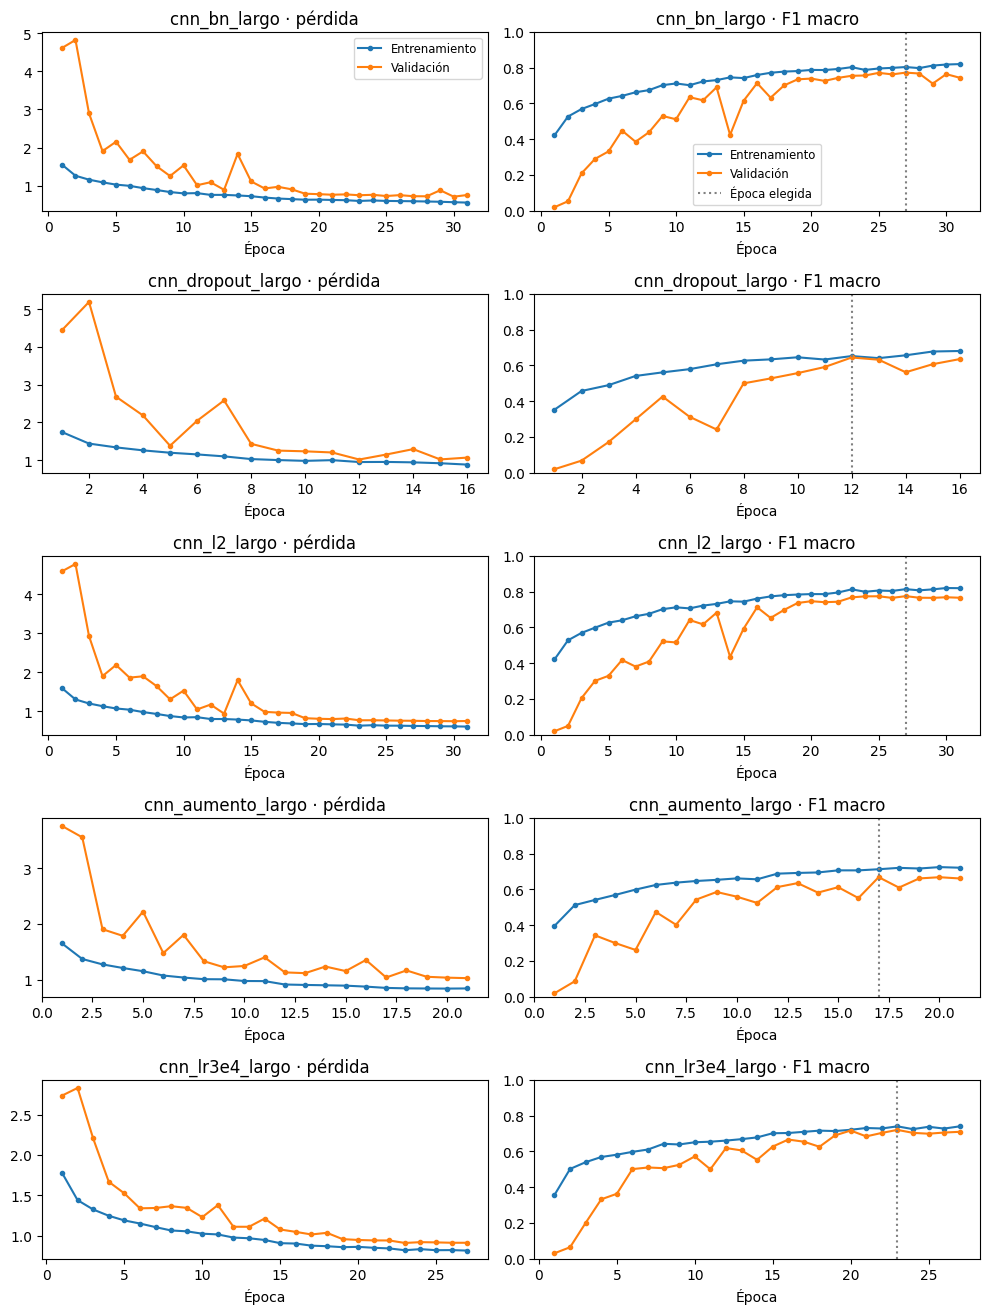

In [ ]:
def run_scratch_largo(run, spec, learning_rate=1e-3):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_scratch(**spec)
    train_model(model, run, "CNN propia", "desde cero (largo)", learning_rate, EPOCHS["cnn_largo"])
    scratch_specs[run] = spec


complementary = []
reference = "cnn_bn_largo"
run_scratch_largo(reference, scratch_specs["cnn_batchnorm"])
long_runs = [reference]

for name, change, update, lr in [
    ("cnn_dropout_largo", "Dropout 0,30 (sin L2)", {"dropout": 0.30}, 1e-3),
    ("cnn_l2_largo", "L2 1e-4 (sin dropout)", {"l2": 1e-4}, 1e-3),
    ("cnn_aumento_largo", "Aumento geométrico", {"augmented": True}, 1e-3),
    ("cnn_lr3e4_largo", "Tasa de aprendizaje 3e-4", {}, 3e-4),
]:
    run_scratch_largo(name, {**scratch_specs[reference], **update}, learning_rate=lr)
    long_runs.append(name)
    chosen = compare_validation(name, reference, change)
    complementary.append({
        "cambio": change, "referencia": reference, "candidata": name,
        "delta_f1_val": runs[name]["f1_val"] - runs[reference]["f1_val"],
        "elegida": chosen,
    })
    reference = chosen

# La CNN propia que pasa a test es la de mejor F1 de validación entre todos los experimentos desde cero.
scratch_winner = max(scratch_specs, key=lambda run: runs[run]["f1_val"])
print(f"CNN propia elegida tras los experimentos complementarios: {scratch_winner}")
display(pd.DataFrame(complementary).round(4))
display(pd.DataFrame.from_dict({run: runs[run] for run in long_runs}, orient="index").round(4))
show_curves(long_runs)

### Análisis de los experimentos complementarios

| Experimento | Cambio | Épocas (mejor) | F1 train | F1 val | Brecha | Δ F1 val frente a su referencia |
|---|---|---|---|---|---|---|
| `cnn_bn_largo` | `cnn_batchnorm` con hasta 40 épocas | 31 (27) | 0,80 | 0,77 | +0,03 | **+0,09** frente a `cnn_batchnorm` |
| `cnn_dropout_largo` | + dropout 0,30 | 16 (12) | 0,65 | 0,64 | +0,01 | −0,13 |
| `cnn_l2_largo` | + L2 1e-4 | 31 (27) | 0,81 | **0,77** | +0,04 | +0,003 → **modelo elegido** |
| `cnn_aumento_largo` | + aumento geométrico | 21 (17) | 0,71 | 0,67 | +0,04 | −0,11 |
| `cnn_lr3e4_largo` | tasa inicial 3e-4 | 27 (23) | 0,74 | 0,72 | +0,02 | −0,05 |

**1. El entrenamiento largo confirma el diagnóstico de subajuste.** Con el mismo modelo, pasar de 15 a un máximo de 40 épocas eleva el F1 de validación de 0,69 a **0,77 (+0,09)**, una de las mayores mejoras de todo el estudio, similar a la que aportó el cuarto bloque convolucional. El *early stopping* se activa en la época 31 (mejor época, la 27), por lo que 40 épocas son suficientes. Buena parte de la ganancia llega cuando `ReduceLROnPlateau` reduce la tasa de aprendizaje: a partir de ahí la validación se mantiene entre 0,73 y 0,77, salvo una caída puntual a 0,71 en la época 29.

**2. Dropout por separado → empeora (−0,13), pero la comparación tiene una limitación.** El modelo se detiene en la época 16 con un F1 de validación de 0,64: la validación oscila tanto que el *early stopping* (paciencia de 4 épocas) corta el entrenamiento antes de que converja. La brecha casi nula (+0,01) confirma que el dropout sí frena la memorización, pero este modelo no la sufría, así que solo añade lentitud.

**3. L2 por separado: sin efecto apreciable (+0,003).** Las curvas de `cnn_l2_largo` y `cnn_bn_largo` son prácticamente idénticas y la brecha no se reduce (+0,04 frente a +0,03). Con una penalización de 1e-4 y un modelo pequeño (80 mil parámetros) que apenas sobreajusta, L2 no tiene un efecto apreciable. La regla de selección lo conserva por una diferencia de tres milésimas, que interpretamos como equivalente.

**4. Aumento de datos → empeora (−0,11).** Se repite el patrón del dropout: la tarea con imágenes transformadas es más difícil, la validación oscila y el *early stopping* detiene el entrenamiento en la época 21. Una hipótesis es que, al ser el encuadre y el fondo similares en todas las fotos, las variaciones geométricas aportan poca información nueva y, en cambio, sí ralentizan el aprendizaje.

**5. Una tasa de aprendizaje menor (3e-4) estabiliza la validación, pero no mejora el resultado (−0,05).** Con la tasa más baja desaparece la caída brusca de la validación que se repetía en la época 14 con 1e-3 (de 0,69 a 0,42), y la brecha es pequeña (+0,02). A cambio, el modelo converge más despacio y el *early stopping* lo detiene en la época 27 con 0,72. Empezar con 1e-3 y dejar que `ReduceLROnPlateau` la reduzca resulta más eficaz.

**Modelo final de la CNN propia: `cnn_l2_largo`** (4 bloques convolucionales con batch normalization, L2 de 1e-4 y entrenamiento largo), con un F1 macro de validación de **0,77**, frente a 0,69 del mejor modelo de la sección 5.

**Lecciones del proceso.** (1) Antes de añadir regularización hay que comprobar que el modelo sobreajusta: aquí el problema era el contrario. (2) Con curvas de validación tan ruidosas, un *early stopping* con paciencia de 4 épocas puede penalizar a las técnicas que ralentizan el aprendizaje. Una paciencia mayor permitiría compararlas en igualdad de condiciones.

## 6. CNN preentrenadas en ImageNet

**MobileNetV2** usa bloques residuales invertidos con convoluciones separables, y **EfficientNetB0**, bloques MBConv con atención de canales. Para que la comparación sea justa, ambas reciben la misma resolución, la misma cabeza de clasificación (*global average pooling* y dropout de 0,30) y el mismo aumento geométrico. MobileNetV2 reescala la entrada a [−1, 1], mientras que EfficientNetB0 incorpora su propio preprocesamiento y recibe valores en [0, 255].

Para cada arquitectura seguimos dos fases:

1. **Transfer learning.** Congelamos toda la base y entrenamos solo la cabeza, con una tasa de aprendizaje de 0,001.
2. **Fine-tuning.** Partimos de la mejor cabeza y descongelamos el último grupo de convoluciones. Mantenemos congeladas las capas de normalización de la base y reducimos la tasa a 0,00001 para limitar el cambio en los pesos preentrenados.

En cada arquitectura nos quedamos con la fase de mayor F1 macro de validación; así medimos si el fine-tuning aporta una mejora antes de usar el test.

Referencias: [Guía de Keras](https://keras.io/guides/transfer_learning/) · [MobileNetV2](https://keras.io/api/applications/mobilenet/) · [EfficientNetB0](https://keras.io/api/applications/efficientnet/).

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "realwaste_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala_mobilenet (Rescaling)    │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (4 outputs left out)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

EfficientNetB0_transfer: 11,529 parámetros entrenables | LR=0.001
Epoch 1/12
104/104 - 19s - 186ms/step - accuracy: 0.4739 - f1_macro: 0.4562 - loss: 1.4831 - val_accuracy: 0.6728 - val_f1_macro: 0.6583 - val_loss: 1.0084 - learning_rate: 0.0010
Epoch 2/12
104/104 - 5s - 44ms/step - accuracy: 0.6641 - f1_macro: 0.6600 - loss: 0.9794 - val_accuracy: 0.7177 - val_f1_macro: 0.7064 - val_loss: 0.8378 - learning_rate: 0.0010
Epoch 3/12
104/104 - 4s - 43ms/step - accuracy: 0.7121 - f1_macro: 0.7110 - loss: 0.8322 - val_accuracy: 0.7542 - val_f1_macro: 0.7437 - val_loss: 0.7710 - learning_rate: 0.0010
Epoch 4/12
104/104 - 4s - 40ms/step - accuracy: 0.7446 - f1_macro: 0.7446 - loss: 0.7570 - val_accuracy: 0.7556 - val_f1_macro: 0.7481 - val_loss: 0.7179 - learning_rate: 0.0010
Epoch 5/12
104/104 - 5s - 44ms/step - accuracy: 0.7575 - f1_macro: 0.7586 - loss: 0.6960 - val_accuracy: 0.7669 - val_f1_macro: 0.7601 - val_loss: 0.6971 - learning_rate: 0.0010
Epoch 6/12
104/104 - 5s - 46ms/step - accu

,familia,fase,lr_inicial,parametros_totales,parametros_entrenables,epocas,mejor_epoca,segundos,f1_train,f1_val,acc_val,brecha_f1
MobileNetV2_transfer,MobileNetV2,transfer learning,0.001,2269513,11529,12,11,46.4055,0.8248,0.7633,0.7654,0.0615
MobileNetV2_fine_tuning,MobileNetV2,fine-tuning,0.000,2269513,890569,10,8,42.2806,0.8756,0.7925,0.7978,0.0831
EfficientNetB0_transfer,EfficientNetB0,transfer learning,0.001,4061100,11529,11,7,62.7142,0.7883,0.7768,0.7837,0.0115
EfficientNetB0_fine_tuning,EfficientNetB0,fine-tuning,0.000,4061100,1133113,10,10,57.8636,0.8442,0.7842,0.7893,0.0600


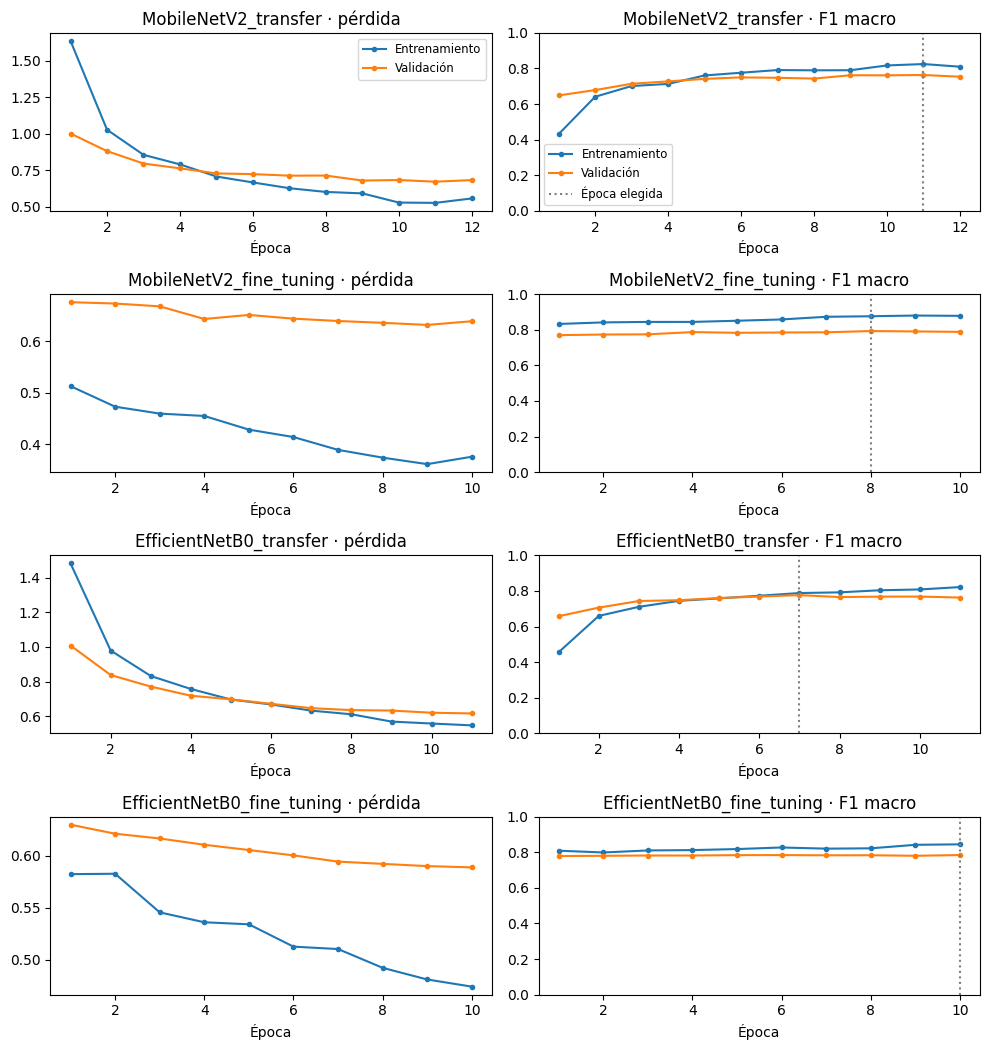

In [ ]:
BACKBONES = {
    "MobileNetV2": {
        "factory": keras.applications.MobileNetV2,
        "prefixes": ("block_16_", "Conv_1"),
    },
    "EfficientNetB0": {
        "factory": keras.applications.EfficientNetB0,
        "prefixes": ("block7a_", "top_conv"),
    },
}


def build_pretrained(family):
    base = BACKBONES[family]["factory"](
        include_top=False, weights="imagenet", input_shape=(*IMAGE_SIZE, 3),
    )
    base.trainable = False
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="imagen")
    x = augmentation()(inputs)
    if family == "MobileNetV2":
        x = layers.Rescaling(1 / 127.5, offset=-1, name="escala_mobilenet")(x)

    # Se mantiene la base en modo inferencia durante el ajuste fino.
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"realwaste_{family.lower()}"), base


def unfreeze_last_group(base, family):
    prefixes = BACKBONES[family]["prefixes"]
    base.trainable = True
    for layer in base.layers:
        layer.trainable = (
            layer.name.startswith(prefixes) and not isinstance(layer, layers.BatchNormalization)
        )
    trainable = [layer.name for layer in base.layers if layer.trainable_weights]
    if not trainable:
        raise RuntimeError(f"No se encontraron pesos para descongelar en {family}.")
    print(f"Capas de {family} con pesos entrenables: {', '.join(trainable)}")


transfer_winners = {}
transfer_runs = []
for family in BACKBONES:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model, base = build_pretrained(family)
    frozen_run = f"{family}_transfer"
    tuned_run = f"{family}_fine_tuning"
    model.summary()
    train_model(model, frozen_run, family, "transfer learning", 1e-3, EPOCHS["transfer"])
    unfreeze_last_group(base, family)
    train_model(model, tuned_run, family, "fine-tuning", 1e-5, EPOCHS["fine_tuning"])
    transfer_winners[family] = compare_validation(tuned_run, frozen_run, f"Ajuste fino de {family}")
    transfer_runs.extend([frozen_run, tuned_run])
    del model, base

display(pd.DataFrame.from_dict({run: runs[run] for run in transfer_runs}, orient="index").round(4))
show_curves(transfer_runs)

### Análisis de transfer learning y fine-tuning

| Modelo | Fase | Parámetros entrenables | F1 train | F1 val | Brecha | Mejor época | Pérdida val | Tiempo |
|---|---|---|---|---|---|---|---|---|
| MobileNetV2 | Transfer learning | 11.529 | 0,82 | 0,76 | +0,06 | 11 de 12 | 0,67 | 46 s |
| MobileNetV2 | Fine-tuning | 890.569 | 0,88 | **0,79** | +0,08 | 8 de 10 | 0,64 | 42 s |
| EfficientNetB0 | Transfer learning | 11.529 | 0,79 | 0,78 | +0,01 | 7 de 11 | 0,65 | 63 s |
| EfficientNetB0 | Fine-tuning | 1.133.113 | 0,84 | 0,78 | +0,06 | 10 de 10 | 0,59 | 58 s |

**1. El conocimiento previo de ImageNet acelera mucho el aprendizaje.** Entrenando solo la cabeza (11.529 parámetros entrenables, frente a 80.057 de la CNN propia), ambas redes alcanzan en la **primera época** un F1 de validación de 0,65–0,66 y superan 0,71 en la tercera. La CNN propia necesitó unas 16 épocas para llegar a 0,71 y 27 para alcanzar su mejor valor (0,77). Las características que las redes preentrenadas aprendieron con millones de imágenes (bordes, texturas, formas) son útiles para distinguir materiales aunque ImageNet no contenga estas categorías.

**2. Transfer learning.** EfficientNetB0 generaliza especialmente bien: brecha de apenas +0,01 y mejor época en la 7, tras la cual el *early stopping* detiene el entrenamiento. MobileNetV2 llega a un F1 de validación algo menor (0,76) con una brecha de +0,06.

**3. Fine-tuning.** Optamos por un descongelado **selectivo** (el último bloque de cada red), una de las dos modalidades que admite el enunciado junto con la progresiva. Descongelar el último bloque con una tasa muy baja (1e-5) y la normalización por lotes congelada mejora ambas redes, aunque de forma desigual: **+0,03** en MobileNetV2 y solo **+0,01** en EfficientNetB0. En los dos casos **la brecha aumenta** (de +0,06 a +0,08 y de +0,01 a +0,06): al liberar cientos de miles de parámetros con solo 3.328 imágenes de entrenamiento, el modelo empieza a ajustarse a particularidades del conjunto de entrenamiento. Es un sobreajuste leve; la tasa baja y el aumento de datos probablemente lo limitan, aunque no evaluamos su efecto por separado. En EfficientNetB0 la mejor época fue la última (10 de 10): el F1 de validación apenas varió (de 0,779 a 0,784), pero la pérdida de validación seguía bajando, así que su fine-tuning podría mejorar ligeramente con más épocas. La cabeza usa siempre aumento geométrico y dropout de 0,30; en estas redes no evaluamos su efecto por separado, porque en la fase de transfer learning la brecha era pequeña en EfficientNetB0 (+0,01) y moderada en MobileNetV2 (+0,06).

### Comparación de las dos arquitecturas preentrenadas

Según la regla de selección por F1 macro de validación, la elegida es **MobileNetV2 con fine-tuning (0,793)**, frente a **EfficientNetB0 con fine-tuning (0,784)**. Sin embargo, la diferencia es **menor a un punto** sobre 712 imágenes de validación, lo que en la práctica es un empate. Otros indicadores de validación favorecen a EfficientNetB0: **menor pérdida de validación** (0,59 frente a 0,64) y **menor brecha** entre entrenamiento y validación. A cambio, EfficientNetB0 es más pesada (4,1 millones de parámetros frente a 2,3) y tarda alrededor de un 40 % más en entrenarse (121 s frente a 88 s). En la sección 7 comprobamos cuál de las dos generaliza mejor en datos no vistos.

## 7. Evaluación final sobre test

Evaluamos sobre el conjunto de test el clasificador trivial, la CNN propia seleccionada y la mejor variante (según validación) de cada red preentrenada. Además de la exactitud y el F1 macro, comparamos el *recall* de cada clase y sus principales confusiones. La entropía cruzada de test se calcula con las probabilidades de cada red y sin las penalizaciones de entrenamiento, para que sea comparable entre modelos.

Referencia mayoritaria: Plastic


,accuracy,f1_macro,entropia_cruzada,f1_val,mejor_epoca,brecha_f1
modelo,,,,,,
Clase mayoritaria,0.1938,0.0361,NaN,NaN,NaN,NaN
cnn_l2_largo,0.7542,0.7492,0.7039,0.7747,27.0,0.0391
MobileNetV2_fine_tuning,0.7570,0.7564,0.6844,0.7925,8.0,0.0831
EfficientNetB0_fine_tuning,0.7921,0.7920,0.6083,0.7842,10.0,0.0600


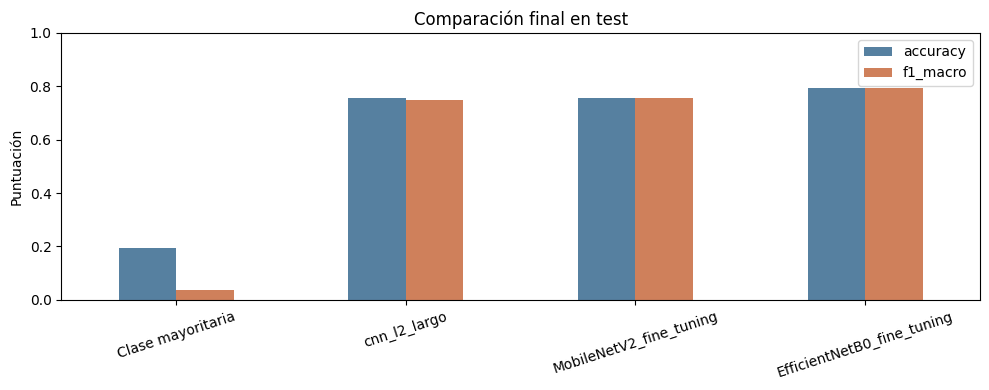

In [ ]:
def scores_from_matrix(matrix):
    support = matrix.sum(axis=1)
    predicted = matrix.sum(axis=0)
    tp = np.diag(matrix)
    precision = np.divide(tp, predicted, out=np.zeros(NUM_CLASSES), where=predicted != 0)
    recall = np.divide(tp, support, out=np.zeros(NUM_CLASSES), where=support != 0)
    f1 = np.divide(2 * tp, support + predicted, out=np.zeros(NUM_CLASSES), where=support + predicted != 0)
    details = pd.DataFrame(
        {"soporte": support, "precision": precision, "recall": recall, "f1": f1},
        index=pd.Index(CLASS_NAMES, name="clase"),
    )
    scores = {"accuracy": float(tp.sum() / matrix.sum()), "f1_macro": float(f1.mean())}
    return scores, details


def register_test(run, predictions, probabilities=None):
    matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    np.add.at(matrix, (y_test, predictions), 1)
    scores, details = scores_from_matrix(matrix)
    scores["entropia_cruzada"] = np.nan
    if probabilities is not None:
        true_probs = probabilities[np.arange(len(y_test)), y_test]
        scores["entropia_cruzada"] = float(-np.log(np.clip(true_probs, 1e-7, 1.0)).mean())

    matrices[run] = matrix
    class_reports[run] = details
    test_rows[run] = scores


y_test = splits["test"]["etiqueta"].to_numpy()
majority = CLASS_NAMES.index(split_counts["train"].idxmax())
finalists = [scratch_winner, *transfer_winners.values()]
matrices, class_reports, test_rows = {}, {}, {}

print(f"Referencia mayoritaria: {CLASS_NAMES[majority]}")
register_test("Clase mayoritaria", np.full(y_test.shape, majority))

for run in finalists:
    keras.backend.clear_session()
    family = runs[run]["familia"]
    if family == "CNN propia":
        model = build_scratch(**scratch_specs[run])
    else:
        # Se reconstruye la misma arquitectura y se recuperan todos los pesos entrenados.
        model, _ = build_pretrained(family)
    model.load_weights(weight_paths[run])
    probabilities = model.predict(test_ds, verbose=0)
    assert probabilities.shape == (len(y_test), NUM_CLASSES)
    assert np.isfinite(probabilities).all()
    register_test(run, probabilities.argmax(axis=1), probabilities)
    del model

results = pd.DataFrame.from_dict(test_rows, orient="index").rename_axis("modelo")
results = results.join(
    pd.DataFrame.from_dict(runs, orient="index")[["f1_val", "mejor_epoca", "brecha_f1"]],
)
results.to_csv(RUN_DIR / "resultados_test.csv")
display(results.round(4))

ax = results[["accuracy", "f1_macro"]].plot.bar(
    figsize=(10, 4), color=["#5680a0", "#cf805b"], rot=18,
)
ax.set(ylabel="Puntuación", xlabel="", ylim=(0, 1), title="Comparación final en test")
plt.tight_layout()
plt.show()

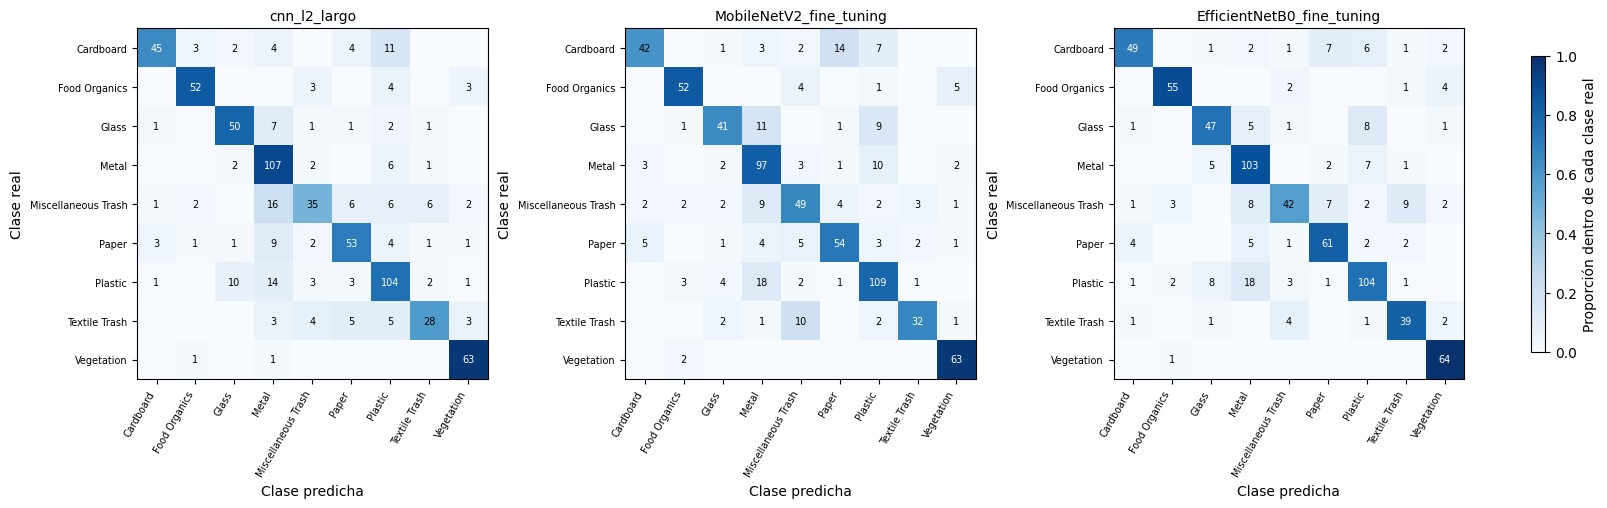

,soporte_test,cnn_l2_largo,MobileNetV2_fine_tuning,EfficientNetB0_fine_tuning
clase,,,,
Cardboard,69,0.652,0.609,0.710
Food Organics,62,0.839,0.839,0.887
Glass,63,0.794,0.651,0.746
Metal,118,0.907,0.822,0.873
Miscellaneous Trash,74,0.473,0.662,0.568
Paper,75,0.707,0.720,0.813
Plastic,138,0.754,0.790,0.754
Textile Trash,48,0.583,0.667,0.812
Vegetation,65,0.969,0.969,0.985


In [ ]:
fig, axes = plt.subplots(1, len(finalists), figsize=(16, 5), layout="constrained")
for run, ax in zip(finalists, axes):
    matrix = matrices[run]
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    heatmap = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(run, fontsize=10)
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=7)
    ax.set(xlabel="Clase predicha", ylabel="Clase real")
    for i, j in np.ndindex(matrix.shape):
        if matrix[i, j]:
            color = "white" if normalized[i, j] > 0.65 else "black"
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color=color, fontsize=7)
fig.colorbar(heatmap, ax=axes.tolist(), shrink=0.75, label="Proporción dentro de cada clase real")
plt.show()

recall_table = pd.DataFrame({run: class_reports[run]["recall"] for run in finalists})
recall_table.insert(0, "soporte_test", class_reports[scratch_winner]["soporte"])
display(recall_table.round(3))
for run in finalists:
    class_reports[run].to_csv(RUN_DIR / f"{run}_clases_test.csv")

### Análisis de la evaluación en test

| Modelo | F1 val | F1 test | Diferencia | Entropía cruzada test |
|---|---|---|---|---|
| Clasificador trivial (siempre "Plastic") | — | 0,04 | — | — |
| CNN propia (`cnn_l2_largo`) | 0,77 | 0,75 | −0,03 | 0,70 |
| MobileNetV2 con fine-tuning | 0,79 | 0,76 | −0,04 | 0,68 |
| EfficientNetB0 con fine-tuning | 0,78 | **0,79** | +0,01 | **0,61** |

**1. Todos los modelos aprenden patrones reales.** El clasificador trivial obtiene un F1 macro de 0,04. Los tres modelos lo superan con amplitud, sobre imágenes que no se usaron en el entrenamiento ni en la selección.

**2. Con un entrenamiento adecuado, la CNN propia queda muy cerca de MobileNetV2.** En test, la diferencia entre ambas es de menos de un punto (0,749 frente a 0,756). EfficientNetB0 obtiene la mejor puntuación (0,792) y la menor entropía cruzada, es decir, la que asigna probabilidades más fiables a la clase correcta. Su ventaja de 3 a 4 puntos sobre las otras dos (unas 25 imágenes) es coherente con sus mejores métricas por clase, pero con una sola semilla y 712 imágenes de test (un error típico cercano a 1,5 puntos) no es concluyente.

**3. La validación sobreestimó a MobileNetV2.** EfficientNetB0 mantiene en test el mismo rendimiento que en validación. MobileNetV2 cae casi 4 puntos y la CNN propia unos 3, de modo que la preentrenada elegida por validación no es la mejor en test. Elegir el mejor de varios candidatos por una diferencia mínima en validación tiende a favorecer al que tuvo una validación "afortunada", y la mayor brecha de entrenamiento de MobileNetV2 ya advertía de un ligero sobreajuste. **No cambiamos la elección a partir del test**, porque eso convertiría al test en un segundo conjunto de validación, pero sí lo reportamos: con un conjunto de validación de este tamaño, diferencias menores a un punto no permiten distinguir entre arquitecturas.

**4. Análisis por clase (recall en test).**

| Clase | Soporte | CNN propia | MobileNetV2 | EfficientNetB0 |
|---|---|---|---|---|
| Cardboard | 69 | 0,65 | 0,61 | **0,71** |
| Food Organics | 62 | 0,84 | 0,84 | **0,89** |
| Glass | 63 | **0,79** | 0,65 | 0,75 |
| Metal | 118 | **0,91** | 0,82 | 0,87 |
| Miscellaneous Trash | 74 | 0,47 | **0,66** | 0,57 |
| Paper | 75 | 0,71 | 0,72 | **0,81** |
| Plastic | 138 | 0,75 | **0,79** | 0,75 |
| Textile Trash | 48 | 0,58 | 0,67 | **0,81** |
| Vegetation | 65 | 0,97 | 0,97 | **0,99** |

- **Vegetation** es la clase más fácil para todos (recall de 0,97 a 0,99), probablemente por su color verde y su forma.
- **Miscellaneous Trash** es la más difícil: es una categoría "cajón de sastre" sin un patrón visual propio. Con la CNN propia su recall es 0,47 y su error más frecuente es confundirla con **Metal** (16 de 74 casos).
- **Textile Trash**, la clase minoritaria, es donde más se nota el preentrenamiento: su recall pasa de 0,58 con la CNN propia a 0,81 con EfficientNetB0.
- La CNN propia es la mejor en **Metal** (0,91) y **Glass** (0,79). Su ventaja está en clases con muchos ejemplos o con rasgos visuales muy marcados (brillo, transparencia), mientras que las preentrenadas destacan en las clases pequeñas o heterogéneas.
- **Plastic → Metal** es una confusión común a los tres modelos (14, 18 y 18 casos de 138 en la CNN propia, MobileNetV2 y EfficientNetB0), y en MobileNetV2 es su error más frecuente. Una explicación posible, que no verificamos revisando las imágenes mal clasificadas, son los envases con superficies brillantes o metalizadas; algo parecido podría ocurrir con Glass, que también se confunde con Metal y con Plastic.

**Contraste con las hipótesis de la inspección** (matrices de confusión):

| Hipótesis | Resultado |
|---|---|
| *Miscellaneous* ↔ *Textile* | **Se confirma en parte.** Es el error principal de Miscellaneous en EfficientNetB0 (9 casos) y MobileNetV2 confunde 10 textiles con Miscellaneous. En la CNN propia pesa más la confusión con Metal. |
| *Cardboard* ↔ *Paper* | **Se confirma en las preentrenadas.** MobileNetV2 clasifica 14 de 69 cartones como papel, y EfficientNetB0, 7. La CNN propia confunde más el cartón con Plastic (11 casos). |
| *Plastic* ↔ *Paper* | **No se confirma.** Las confusiones entre ambas clases son de 1 a 4 casos en todos los modelos. |
| No anticipada: *Plastic* ↔ *Metal* | Es la confusión más repetida del estudio, como se describe arriba. |

## 8. Interpretación y conclusiones

La celda siguiente genera automáticamente, a partir de la ejecución, un resumen con las cifras clave: el efecto de cada cambio en la CNN propia, la aportación del fine-tuning, la comparación final en test y las brechas entre entrenamiento y validación. A continuación presentamos nuestra interpretación y las conclusiones del trabajo.

In [ ]:
best_transfer = max(transfer_winners.values(), key=lambda run: runs[run]["f1_val"])
own_test = test_rows[scratch_winner]["f1_macro"]
pretrained_test = test_rows[best_transfer]["f1_macro"]
delta = pretrained_test - own_test
dummy_f1 = test_rows["Clase mayoritaria"]["f1_macro"]
minority = split_counts["train"].idxmin()
minority_own = class_reports[scratch_winner].loc[minority, "recall"]
minority_pretrained = class_reports[best_transfer].loc[minority, "recall"]


def describe_confusion(run):
    matrix = matrices[run].copy()
    np.fill_diagonal(matrix, 0)
    real, predicted = np.unravel_index(matrix.argmax(), matrix.shape)
    count = int(matrix[real, predicted])
    if count == 0:
        return f"**{run}** acertó todos los ejemplos del test."
    total = int(matrices[run][real].sum())
    return f"En **{run}**, el error más frecuente fue *{CLASS_NAMES[real]}* como *{CLASS_NAMES[predicted]}* ({count} de {total})."


lines = [f"**Perfil ejecutado:** `{PROFILE}`."]
if QUICK:
    lines.append("**Verificación técnica.** El subconjunto y la única época sirven para probar la ejecución. Las puntuaciones de esta corrida carecen de valor para elegir el modelo de la entrega.")

lines.append("### Cambios en la CNN propia")
for comparison in scratch_comparisons:
    lines.append(
        f"- {comparison['cambio']}: {comparison['delta_f1_val']:+.3f} en F1 macro "
        f"de validación frente a `{comparison['referencia']}`. "
        f"Variante retenida: `{comparison['elegida']}`."
    )

lines.append("### Efecto del ajuste fino")
for family, chosen in transfer_winners.items():
    frozen = runs[f"{family}_transfer"]
    tuned = runs[f"{family}_fine_tuning"]
    fine_delta = tuned["f1_val"] - frozen["f1_val"]
    lines.append(
        f"- **{family}:** {fine_delta:+.3f} en F1 macro de validación tras el ajuste fino. "
        f"Se elige `{chosen}`. Entrenar cabeza y ajuste fino llevó "
        f"{frozen['segundos']:.1f} s y {tuned['segundos']:.1f} s respectivamente."
    )

lines.extend([
    "### Comparación final",
    f"- **Selección por validación:** `{best_transfer}` entre las preentrenadas "
    f"(F1 macro {runs[best_transfer]['f1_val']:.3f}) y `{scratch_winner}` "
    f"entre las propias ({runs[scratch_winner]['f1_val']:.3f}).",
    f"- **Generalización en test:** F1 macro de {pretrained_test:.3f} para la preentrenada "
    f"elegida y {own_test:.3f} para la CNN propia. Diferencia de la preentrenada frente a la "
    f"propia: {delta:+.3f}. Referencia mayoritaria: {dummy_f1:.3f}.",
    f"- **Clase minoritaria ({minority}):** recall en test de {minority_own:.1%} "
    f"con la CNN propia y {minority_pretrained:.1%} con la preentrenada elegida.",
    f"- {describe_confusion(scratch_winner)} {describe_confusion(best_transfer)}",
])

for run in finalists:
    lines.append(
        f"- Brecha de F1 entre entrenamiento y validación en la época elegida para "
        f"`{run}`: {runs[run]['brecha_f1']:+.3f}."
    )

lines.append(
    "### Alcance\n"
    "La comparación usa una semilla y una partición del mismo vertedero. "
    "La generalización a otros lugares o campañas requiere datos independientes. "
    "Los cambios de F1 deben interpretarse junto con el soporte por clase, las curvas "
    "y los costes de entrenamiento."
)
display(Markdown("\n\n".join(lines)))

**Perfil ejecutado:** `completo`.

### Cambios en la CNN propia

- Cuarto bloque convolucional: +0.094 en F1 macro de validación frente a `cnn_base`. Variante retenida: `cnn_profundidad`.

- Batch normalization: +0.074 en F1 macro de validación frente a `cnn_profundidad`. Variante retenida: `cnn_batchnorm`.

- L2 y dropout: -0.046 en F1 macro de validación frente a `cnn_batchnorm`. Variante retenida: `cnn_batchnorm`.

- Aumento geométrico: -0.054 en F1 macro de validación frente a `cnn_batchnorm`. Variante retenida: `cnn_batchnorm`.

### Efecto del ajuste fino

- **MobileNetV2:** +0.029 en F1 macro de validación tras el ajuste fino. Se elige `MobileNetV2_fine_tuning`. Entrenar cabeza y ajuste fino llevó 46.4 s y 42.3 s respectivamente.

- **EfficientNetB0:** +0.007 en F1 macro de validación tras el ajuste fino. Se elige `EfficientNetB0_fine_tuning`. Entrenar cabeza y ajuste fino llevó 62.7 s y 57.9 s respectivamente.

### Comparación final

- **Selección por validación:** `MobileNetV2_fine_tuning` entre las preentrenadas (F1 macro 0.792) y `cnn_l2_largo` entre las propias (0.775).

- **Generalización en test:** F1 macro de 0.756 para la preentrenada elegida y 0.749 para la CNN propia. Diferencia de la preentrenada frente a la propia: +0.007. Referencia mayoritaria: 0.036.

- **Clase minoritaria (Textile Trash):** recall en test de 58.3% con la CNN propia y 66.7% con la preentrenada elegida.

- En **cnn_l2_largo**, el error más frecuente fue *Miscellaneous Trash* como *Metal* (16 de 74). En **MobileNetV2_fine_tuning**, el error más frecuente fue *Plastic* como *Metal* (18 de 138).

- Brecha de F1 entre entrenamiento y validación en la época elegida para `cnn_l2_largo`: +0.039.

- Brecha de F1 entre entrenamiento y validación en la época elegida para `MobileNetV2_fine_tuning`: +0.083.

- Brecha de F1 entre entrenamiento y validación en la época elegida para `EfficientNetB0_fine_tuning`: +0.060.

### Alcance
La comparación usa una semilla y una partición del mismo vertedero. La generalización a otros lugares o campañas requiere datos independientes. Los cambios de F1 deben interpretarse junto con el soporte por clase, las curvas y los costes de entrenamiento.

### Conclusiones

**1. Las redes preentrenadas con fine-tuning obtuvieron los mejores resultados, aunque la arquitectura elegida cambia según la partición.** La regla de selección por F1 macro de validación eligió MobileNetV2 (0,7925), frente a EfficientNetB0 (0,7842). En la evaluación final, EfficientNetB0 obtuvo el mayor F1 macro de test (0,7920), seguido de MobileNetV2 (0,7564) y la CNN propia (0,7492). Por tanto, EfficientNetB0 fue el modelo con mejor rendimiento observado en nuestro test. Con una sola semilla, estos resultados requieren más repeticiones para confirmar que su ventaja se mantiene.

**2. El proceso experimental fue tan decisivo como la arquitectura.** Con 15 épocas, la CNN propia parecía claramente inferior (0,69 en validación). Al diagnosticar que su problema era el **subajuste** y no el sobreajuste, el entrenamiento largo la llevó a 0,77 en validación y 0,75 en test, a la par de MobileNetV2. Por la misma razón, ninguna de las técnicas pensadas contra el sobreajuste (L2, dropout y aumento de datos) la mejoró: atacaban un problema que el modelo no tenía. Solo batch normalization aportó (+0,07), probablemente porque estabiliza y acelera el entrenamiento. Las preentrenadas mostraron el riesgo contrario, un **sobreajuste leve** al descongelar capas en el fine-tuning.

**3. Con conjuntos pequeños, la selección por validación tiene límites.** La regla eligió MobileNetV2 por menos de un punto, pero EfficientNetB0 obtuvo mejores resultados en test. Con más tiempo, convendría repetir la comparación con varias semillas o con validación cruzada antes de decidir entre arquitecturas tan parecidas.

**Ventajas e inconvenientes de cada estrategia**

| | CNN desde cero (`cnn_l2_largo`) | Red preentrenada (EfficientNetB0) |
|---|---|---|
| F1 macro en test | 0,75 | **0,79** |
| Parámetros totales | **80 mil** | 4,1 millones (unas 50 veces más) |
| Épocas hasta la mejor validación | 27 | 7 (transfer learning) + 10 (fine-tuning) |
| Tiempo de entrenamiento (GPU de Colab) | ~90 s | ~2 min (ambas fases) |
| Generalización | Brecha pequeña (+0,04); el límite fue el subajuste | Buena; sobreajuste leve tras el fine-tuning (+0,06) |
| Ventajas | Modelo muy pequeño, diseño totalmente controlado, sin depender de pesos externos; mejor en Metal y Glass | Mejor rendimiento global con pocos datos, converge rápido, mejor en clases minoritarias |
| Inconvenientes | Necesita más épocas y un ajuste cuidadoso para competir | Modelo mucho más pesado; depende de que las características de ImageNet sean transferibles |

**Limitaciones y posibles mejoras**
- Una sola semilla e imágenes de un único vertedero: la generalización a otros entornos no está garantizada.
- La resolución de 128 × 128 px puede ocultar detalles de textura; entrenar las preentrenadas a 224 × 224, su resolución nativa, es una línea de mejora.
- El *early stopping* con paciencia de 4 épocas, ante curvas de validación ruidosas, pudo cortar antes de tiempo los experimentos con dropout y aumento de datos.
- No se exploraron el tamaño del *kernel* ni del lote en la CNN propia, ni la regularización de la cabeza en las preentrenadas.
- La clase *Miscellaneous Trash* es ambigua por definición y limita el rendimiento máximo alcanzable.